# Unidad III — Análisis supervisado

David Rafael Aguilar Solis · 22300607 · 10IDGS-G1

Cuaderno consolidado de lectura de los experimentos existentes. No reentrena modelos ni modifica resultados previos. La fuente de cifras son los CSV/JSON producidos por los experimentos de Unidad III.

## Regresión de Weight
Se reporta el candidato de Random Forest ajustado mediante validación cruzada de entrenamiento, junto con evaluación reservada. Los resultados describen este conjunto y no establecen causalidad ni validez externa.

In [1]:
from pathlib import Path
import pandas as pd, json
ROOT=Path.cwd(); R=ROOT/'docs/unidad_iii/resultados'
reg=pd.read_csv(R/'optimizacion_metricas_test.csv')
print('Columnas disponibles:',reg.columns.tolist())
display(reg)

Columnas disponibles: ['task', 'scenario', 'model', 'best_params', 'cv_best_score', 'test_mae', 'test_rmse', 'test_r2', 'test_accuracy', 'test_precision_macro', 'test_recall_macro', 'test_f1_macro', 'classes']


,task,scenario,model,best_params,cv_best_score,test_mae,test_rmse,test_r2,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,classes
0,regression,all_allowed_features,RandomForestRegressor,"{""model__max_depth"": null, ""model__min_samples...",8.962674,4.750055,8.142818,0.900486,NaN,NaN,NaN,NaN,NaN
1,classification,A,LogisticRegression,"{""model__C"": 10.0}",0.931012,NaN,NaN,NaN,0.962085,0.963421,0.961341,0.961489,Insufficient_Weight|Normal_Weight|Overweight_L...
2,classification,A,RandomForestClassifier,"{""model__max_depth"": null, ""model__min_samples...",0.932616,NaN,NaN,NaN,0.947867,0.947827,0.946327,0.946480,Insufficient_Weight|Normal_Weight|Overweight_L...
3,classification,B,LogisticRegression,"{""model__C"": 10.0}",0.579051,NaN,NaN,NaN,0.637441,0.626072,0.630821,0.608946,Insufficient_Weight|Normal_Weight|Overweight_L...
4,classification,B,RandomForestClassifier,"{""model__max_depth"": null, ""model__min_samples...",0.828691,NaN,NaN,NaN,0.869668,0.866406,0.866938,0.866609,Insufficient_Weight|Normal_Weight|Overweight_L...


## Clasificación: escenarios A y B
A incluye `Height` y `Weight` y tiene riesgo de circularidad con la etiqueta. B excluye ambas variables antropométricas y mide una aproximación basada en hábitos/condición. Se muestran métricas ya calculadas; no se seleccionó modelo usando test.

,task,scenario,model,best_params,cv_best_score,test_mae,test_rmse,test_r2,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,classes
0,regression,all_allowed_features,RandomForestRegressor,"{""model__max_depth"": null, ""model__min_samples...",8.962674,4.750055,8.142818,0.900486,NaN,NaN,NaN,NaN,NaN
1,classification,A,LogisticRegression,"{""model__C"": 10.0}",0.931012,NaN,NaN,NaN,0.962085,0.963421,0.961341,0.961489,Insufficient_Weight|Normal_Weight|Overweight_L...
2,classification,A,RandomForestClassifier,"{""model__max_depth"": null, ""model__min_samples...",0.932616,NaN,NaN,NaN,0.947867,0.947827,0.946327,0.946480,Insufficient_Weight|Normal_Weight|Overweight_L...
3,classification,B,LogisticRegression,"{""model__C"": 10.0}",0.579051,NaN,NaN,NaN,0.637441,0.626072,0.630821,0.608946,Insufficient_Weight|Normal_Weight|Overweight_L...
4,classification,B,RandomForestClassifier,"{""model__max_depth"": null, ""model__min_samples...",0.828691,NaN,NaN,NaN,0.869668,0.866406,0.866938,0.866609,Insufficient_Weight|Normal_Weight|Overweight_L...


Existe reporte base por clase: docs\unidad_iii\resultados\clasificacion_reporte_por_clase_base.json
Matrices de confusión: True


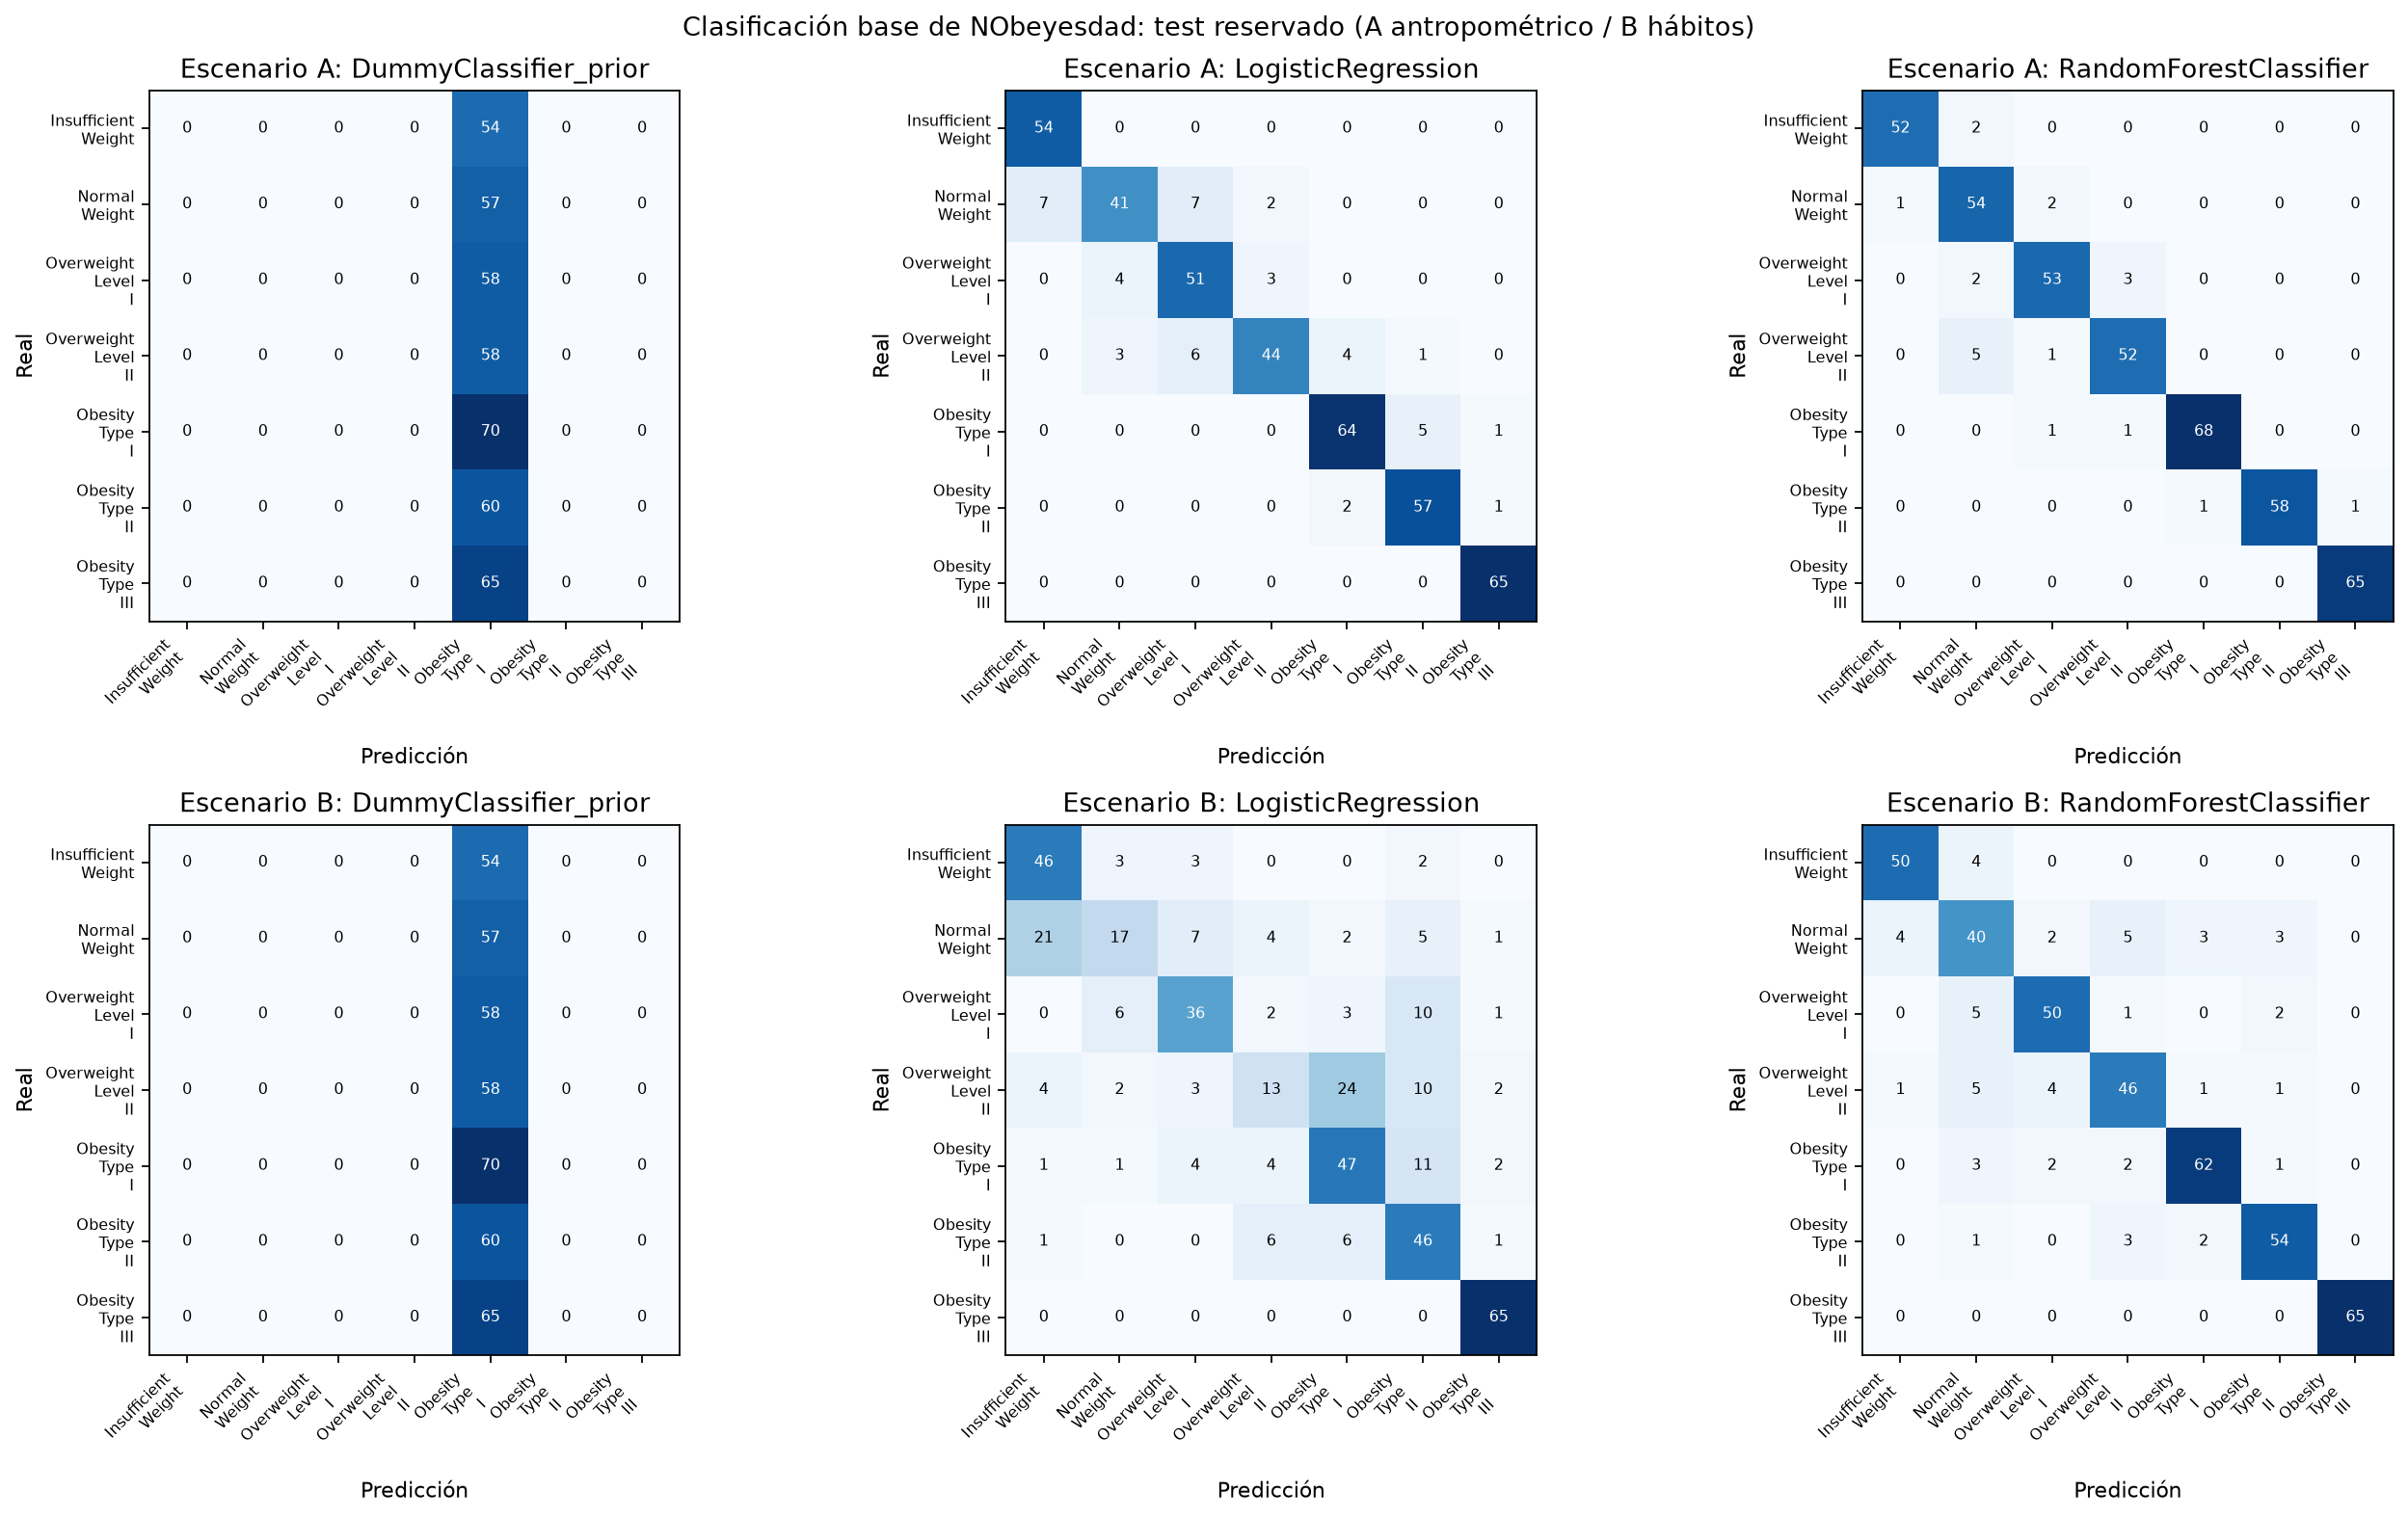

In [2]:
cls=pd.read_csv(R/'optimizacion_metricas_test.csv')
display(cls)
report_path=R/'clasificacion_reporte_por_clase_base.json'
if report_path.exists():
    print('Existe reporte base por clase:',report_path.relative_to(ROOT))
print('Matrices de confusión:',(ROOT/'docs/unidad_iii/figuras/clasificacion_matrices_confusion_base.png').exists())
from IPython.display import Image, display
if (ROOT/'docs/unidad_iii/figuras/clasificacion_matrices_confusion_base.png').exists():
    display(Image(filename=str(ROOT/'docs/unidad_iii/figuras/clasificacion_matrices_confusion_base.png')))

## Interpretación y controles
La comparación debe leer precisión, recall y F1 macro junto con accuracy y matrices por clase. El escenario A no representa una estimación independiente de peso/estatura. El componente sintético y los duplicados limitan la generalización. Consulta el informe completo en `docs/unidad_iii/informe_unidad_iii.md` y la evidencia en `docs/unidad_iii/evidencias/`.